In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Level A — Easy

## A1. Data Types & Attributes

In [2]:
df = pd.read_csv('Penguin_Species_Prediction_Dataset.csv')
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,41.1,18.4,195.0,3886.0,Female
1,Gentoo,Biscoe,50.0,15.4,217.0,4303.0,Male
2,Gentoo,Biscoe,50.0,15.1,220.0,4954.0,Female
3,Chinstrap,Dream,48.7,19.0,196.0,3739.0,Male
4,Adelie,Dream,39.0,17.8,187.0,3607.0,Male


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            1000 non-null   str    
 1   island             1000 non-null   str    
 2   culmen_length_mm   990 non-null    float64
 3   culmen_depth_mm    990 non-null    float64
 4   flipper_length_mm  990 non-null    float64
 5   body_mass_g        990 non-null    float64
 6   sex                990 non-null    str    
dtypes: float64(4), str(3)
memory usage: 54.8 KB


- **species** (Nominal): Penguin species (Adelie, Chinstrap, Gentoo)
- **island** (Nominal): Observation island (Torgersen, Biscoe, Dream)
- **sex** (Nominal): Biological sex (Male/Female)
- **culmen_length_mm** (Continuous): Bill length in mm
- **culmen_depth_mm** (Continuous): Bill depth in mm
- **flipper_length_mm** (Continuous): Flipper length in mm
- **body_mass_g** (Continuous): Body mass in grams

In [4]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
stats = {}

for col in numeric_cols:
    s = df[col].dropna()
    stats[col] = {
        'Mean': s.mean(),
        'Median': s.median(),
        'Mode': s.mode()[0],
        'Range': s.max() - s.min(),
        'Variance': s.var(),
        'Std Dev': s.std(),
        'IQR': s.quantile(0.75) - s.quantile(0.25)
    }

pd.DataFrame(stats).round(2)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
Mean,43.82,17.34,199.22,4103.31
Median,43.80,17.80,195.00,3882.00
Mode,38.30,18.20,189.00,3318.00
Range,23.60,8.40,60.00,3487.00
Variance,28.20,3.17,173.49,497497.17
Std Dev,5.31,1.78,13.17,705.33
IQR,9.30,2.90,23.00,1001.00


**culmen_length_mm**: Mean≈Median (43.82 vs 43.80) suggests symmetric distribution.   
**culmen_depth_mm**: Mean < Median (17.34 < 17.80) indicates left skew.   
**flipper_length_mm**: Mean > Median (199.22 > 195.00) shows right skew.   
**body_mass_g**: Mean > Median (4103 > 3882) indicates positive skew from larger males.   
    
All features show reasonable variability for biological measurements.    

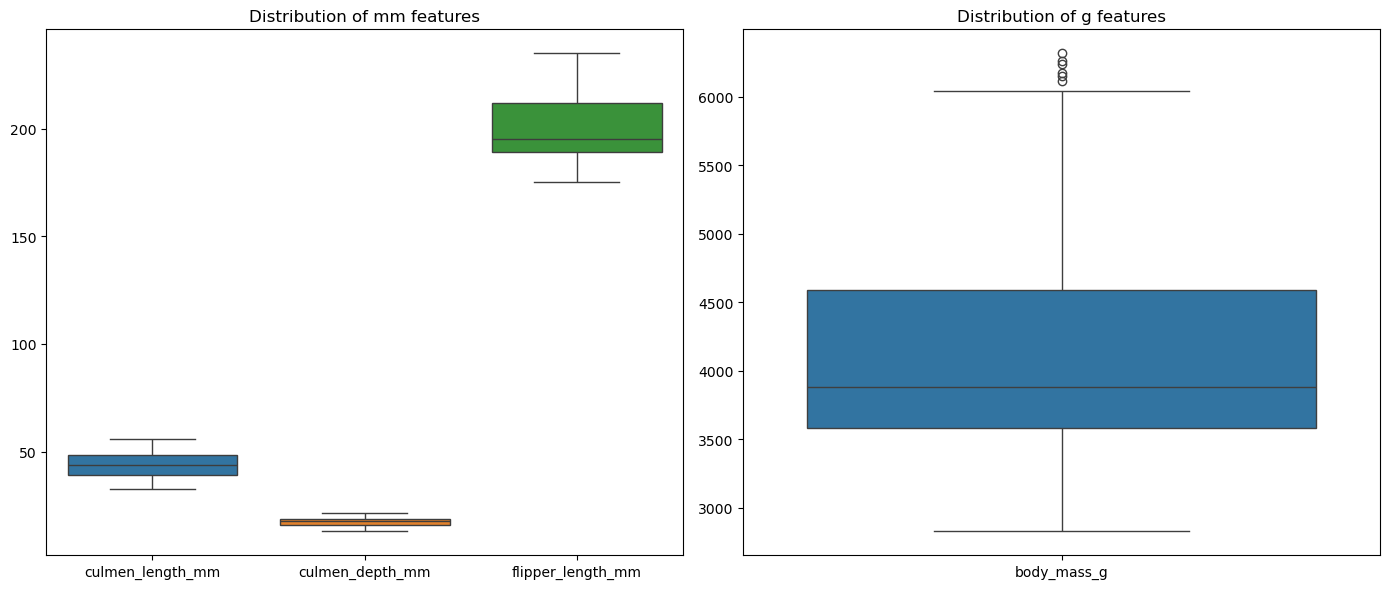

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].set_title("Distribution of mm features")
axes[1].set_title('Distribution of g features')
sns.boxplot(data=df[numeric_cols[:3]], ax=axes[0])
sns.boxplot(data=df[numeric_cols[3:]], ax=axes[1])
plt.tight_layout()
plt.show()

In [6]:
for col in numeric_cols:
    s = df[col].dropna()
    Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
    IQR = Q3 - Q1
    outliers = s[(s < Q1 - 1.5*IQR) | (s > Q3 + 1.5*IQR)]
    print(f'{col}: {len(outliers)} outliers')

culmen_length_mm: 0 outliers
culmen_depth_mm: 0 outliers
flipper_length_mm: 0 outliers
body_mass_g: 6 outliers


Body mass shows 6 high outliers (>6100g), representing exceptionally large male Gentoo penguins.
These are likely valid biological extremes rather than measurement errors.

## A3. Handling Missing Data

In [7]:
df.isnull().sum()

species               0
island                0
culmen_length_mm     10
culmen_depth_mm      10
flipper_length_mm    10
body_mass_g          10
sex                  10
dtype: int64

In [8]:
from sklearn.impute import KNNImputer

missing_cols = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

# Original statistics
orig_stats = df[missing_cols].agg(['mean', 'std']).T
orig_stats.columns = ['Orig_Mean', 'Orig_Std']

# Constant Imputation (0)
df_const = df[missing_cols].fillna(0)
const_stats = df_const.agg(['mean', 'std']).T
const_stats.columns = ['Const_Mean', 'Const_Std']

# Mean Imputation
df_mean = df[missing_cols].fillna(df[missing_cols].mean())
mean_stats = df_mean.agg(['mean', 'std']).T
mean_stats.columns = ['Mean_Imp_Mean', 'Mean_Imp_Std']

# KNN Predictive Imputation (k=5)
knn_imputer = KNNImputer(n_neighbors=5)
df_knn = pd.DataFrame(knn_imputer.fit_transform(df[missing_cols]), columns=missing_cols)
knn_stats = df_knn.agg(['mean', 'std']).T
knn_stats.columns = ['KNN_Mean', 'KNN_Std']

comparison_df = pd.concat([orig_stats, const_stats, mean_stats, knn_stats], axis=1)
comparison_df.round(2)

,Orig_Mean,Orig_Std,Const_Mean,Const_Std,Mean_Imp_Mean,Mean_Imp_Std,KNN_Mean,KNN_Std
culmen_length_mm,43.82,5.31,43.38,6.85,43.82,5.28,43.81,5.29
culmen_depth_mm,17.34,1.78,17.16,2.47,17.34,1.77,17.34,1.78
flipper_length_mm,199.22,13.17,197.23,23.77,199.22,13.11,199.22,13.12
body_mass_g,4103.31,705.33,4062.28,812.02,4103.31,701.80,4102.99,703.59


### Comparison of Imputation Methods

**Constant (0) Imputation:**
- Shifts means downward significantly
- Inflates standard deviation artificially
- Poor choice for biological measurements

**Mean Imputation:**
- Preserves original means exactly
- Slightly reduces standard deviation
- Simple but decreases variance

**KNN Imputation (k=5):**
- Best preserves both means and standard deviations
- Maintains relationships between variables
- Recommended for this dataset

KNN is preferred as it uses similarity between complete observations to estimate missing values.

# Level B — Medium

## B1. Normalization & Standardization

In [9]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

features = ['culmen_length_mm', 'body_mass_g']
df_features = df_knn[features].copy()

minmax_scaler = MinMaxScaler()
zscore_scaler = StandardScaler()

features_minmax = minmax_scaler.fit_transform(df_features)
features_zscore = zscore_scaler.fit_transform(df_features)

results = pd.DataFrame({
    'culmen_length_minmax': features_minmax[:, 0],
    'body_mass_minmax': features_minmax[:, 1],
    'culmen_length_zscore': features_zscore[:, 0],
    'body_mass_zscore': features_zscore[:, 1]
})
results.head()

,culmen_length_minmax,body_mass_minmax,culmen_length_zscore,body_mass_zscore
0,0.368644,0.302839,-0.512957,-0.308560
1,0.745763,0.422426,1.170271,0.284411
2,0.745763,0.609120,1.170271,1.210128
3,0.690678,0.260683,0.924406,-0.517593
4,0.279661,0.222828,-0.910123,-0.705296


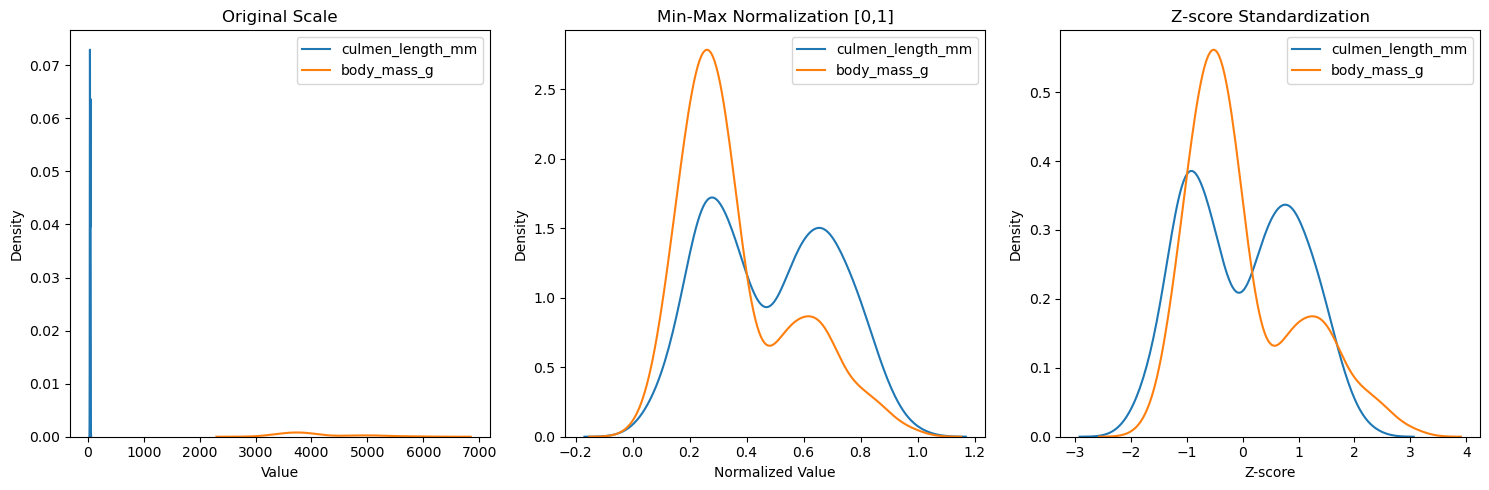

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Original scale
axes[0].set_title('Original Scale')
axes[0].set_xlabel('Value')
for i, col in enumerate(features):
    sns.kdeplot(df_features[col], ax=axes[0], label=col)
axes[0].legend()

# Min-Max scaling
axes[1].set_title('Min-Max Normalization [0,1]')
axes[1].set_xlabel('Normalized Value')
for i, col in enumerate(features):
    sns.kdeplot(features_minmax[:, i], ax=axes[1], label=col)
axes[1].legend()

# Z-score scaling
axes[2].set_title('Z-score Standardization')
axes[2].set_xlabel('Z-score')
for i, col in enumerate(features):
    sns.kdeplot(features_zscore[:, i], ax=axes[2], label=col)
axes[2].legend()

plt.tight_layout()
plt.show()

### Scaling Comparison

**Original Scale:** Body mass (g) values are ~100x larger than culmen length (mm), making culmen length barely visible in joint plots.

**Min-Max Normalization:**
- Transforms features to [0,1] range
- Preserves distribution shapes
- Sensitive to outliers

**Z-score Standardization:**
- Centers at 0 with std dev = 1
- Better handles outliers
- Preserves relative distances

**When to use each:**
- **Min-Max:** Algorithms needing 0-1 input (neural networks, some distance metrics)
- **Z-score:** Algorithms assuming normality (regression, PCA, SVMs, logistic regression)

## B2. Feature Creation & Discretization

In [11]:
df_knn['culmen_ratio'] = df_knn['culmen_length_mm'] / df_knn['culmen_depth_mm']
print('Culmen ratio statistics:')
df_knn['culmen_ratio'].describe().round(2)

Culmen ratio statistics:


count    1000.00
mean        2.57
std         0.49
min         1.71
25%         2.14
50%         2.49
75%         2.95
max         3.86
Name: culmen_ratio, dtype: float64

In [12]:
# Equal-width binning
df_knn['mass_equal_width'] = pd.cut(
    df_knn['body_mass_g'], 
    bins=3, 
    labels=['Low', 'Medium', 'High']
)

# Equal-frequency binning
df_knn['mass_equal_freq'] = pd.qcut(
    df_knn['body_mass_g'], 
    q=3, 
    labels=['Low', 'Medium', 'High']
)

df_knn[['body_mass_g', 'mass_equal_width', 'mass_equal_freq']].head(10)

,body_mass_g,mass_equal_width,mass_equal_freq
0,3886.0,Low,Medium
1,4303.0,Medium,High
2,4954.0,Medium,High
3,3739.0,Low,Medium
4,3607.0,Low,Low
5,3568.0,Low,Low
6,3967.0,Low,Medium
7,4742.0,Medium,High
8,4166.0,Medium,High
9,4688.0,Medium,High


In [13]:
print('Equal-width binning counts:')
print(df_knn['mass_equal_width'].value_counts().sort_index())
print()
print('Equal-frequency binning counts:')
print(df_knn['mass_equal_freq'].value_counts().sort_index())

Equal-width binning counts:
mass_equal_width
Low       578
Medium    311
High      111
Name: count, dtype: int64

Equal-frequency binning counts:
mass_equal_freq
Low       334
Medium    334
High      332
Name: count, dtype: int64


### Discretization Results

**Equal-width:** Creates bins of equal size (2826-3992g, 3992-5154g, 5154-6317g)
- Uneven counts: 578 Low, 311 Medium, 111 High
- Reflects natural distribution of body mass

**Equal-frequency:** Creates bins with equal counts (~334 each)
- Uneven ranges: (2829-3703g, 3703-4146g, 4146-6317g)
- Forces balance regardless of natural distribution

Equal-width better represents the actual data distribution for this dataset.

In [14]:
df_encoded = pd.get_dummies(df[['island', 'sex']], drop_first=True, dtype=int)
print('Encoded shape:', df_encoded.shape)
df_encoded.head()

Encoded shape: (1000, 3)


,island_Dream,island_Torgersen,sex_Male
0,0,1,0
1,0,0,1
2,0,0,0
3,1,0,1
4,1,0,1


### Encoding Results
- island_Dream: 1 if Dream island, 0 otherwise
- island_Torgersen: 1 if Torgersen island, 0 otherwise
  (Biscoe is reference category)
- sex_Male: 1 if Male, 0 if Female

This prepares categorical variables for machine learning algorithms.

# Additional Analytical Tasks

## D1. Measures of Similarity and Dissimilarity

In [15]:
# Pick two penguins
vec_a = df_knn.loc[0, missing_cols].values.astype(float)
vec_b = df_knn.loc[1, missing_cols].values.astype(float)

# 1. Euclidean distance
euclidean = np.sqrt(np.sum((vec_a - vec_b) ** 2))

# 2. Jaccard similarity on categorical attributes
set_a = set(df.loc[0, ['species', 'island', 'sex']])
set_b = set(df.loc[1, ['species', 'island', 'sex']])
jaccard = len(set_a & set_b) / len(set_a | set_b)

# 3. Cosine similarity and Pearson correlation (raw scale)
cosine_raw = np.dot(vec_a, vec_b) / (np.linalg.norm(vec_a) * np.linalg.norm(vec_b))
pearson_raw = np.corrcoef(vec_a, vec_b)[0, 1]

# same two metrics but on standardized features
std_features = zscore_scaler.fit_transform(df_knn[missing_cols])
vec_a_std, vec_b_std = std_features[0], std_features[1]
cosine_std = np.dot(vec_a_std, vec_b_std) / (np.linalg.norm(vec_a_std) * np.linalg.norm(vec_b_std))
pearson_std = np.corrcoef(vec_a_std, vec_b_std)[0, 1]

similarity_table = pd.DataFrame({
    'Metric': ['Euclidean distance', 'Jaccard similarity', 'Cosine similarity (raw)',
               'Pearson correlation (raw)', 'Cosine similarity (standardized)',
               'Pearson correlation (standardized)'],
    'Value': [euclidean, jaccard, cosine_raw, pearson_raw, cosine_std, pearson_std]
})
similarity_table.round(4)

,Metric,Value
0,Euclidean distance,417.6855
1,Jaccard similarity,0.0000
2,Cosine similarity (raw),1.0000
3,Pearson correlation (raw),1.0000
4,Cosine similarity (standardized),-0.9274
5,Pearson correlation (standardized),-0.9240


### Metrics explanation

- **Euclidean distance** — straight-line distance between two numeric vectors, sensitive to scale of each feature.
- **Jaccard similarity** — measures overlap between two categorical attributes, ratio of intersection to union.
- **Cosine similarity** — measures the angle between two vectors, ignores magnitude.
- **Pearson correlation** — measures linear relationship between two vectors, centers data first (mean = 0).

### Why results differ

Raw cosine and Pearson correlation are both ~1.0, this is misleading. `body_mass_g` is thousands while other features are tens, so the vectors point in almost the same direction just because of the mass value, not because the penguins are actually similar. After standardizing the features (mean 0, std 1) cosine and Pearson drop to about -0.93, showing the two penguins are actually quite different once scale is removed.

Jaccard is low (0.0) since these two penguins don't share species, island or sex — none of their categorical attributes match.

## D2. Dimensionality Reduction (PCA)

In [16]:
# Step 1: standardize features
X_std = zscore_scaler.fit_transform(df_knn[missing_cols])

# Step 2: covariance matrix
cov_matrix = np.cov(X_std.T)
pd.DataFrame(cov_matrix, index=missing_cols, columns=missing_cols).round(3)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
culmen_length_mm,1.001,-0.348,0.503,0.372
culmen_depth_mm,-0.348,1.001,-0.750,-0.740
flipper_length_mm,0.503,-0.750,1.001,0.755
body_mass_g,0.372,-0.740,0.755,1.001


In [17]:
# Step 3: eigenvalues and eigenvectors of the covariance matrix
eigvals, eigvecs = np.linalg.eigh(cov_matrix)

# sort descending
order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
eigvecs = eigvecs[:, order]

explained_var = pd.DataFrame({
    'Eigenvalue': eigvals,
    'Explained Variance %': eigvals / eigvals.sum() * 100
}, index=[f'PC{i+1}' for i in range(len(eigvals))])
explained_var.round(2)

,Eigenvalue,Explained Variance %
PC1,2.78,69.42
PC2,0.74,18.57
PC3,0.26,6.50
PC4,0.22,5.51


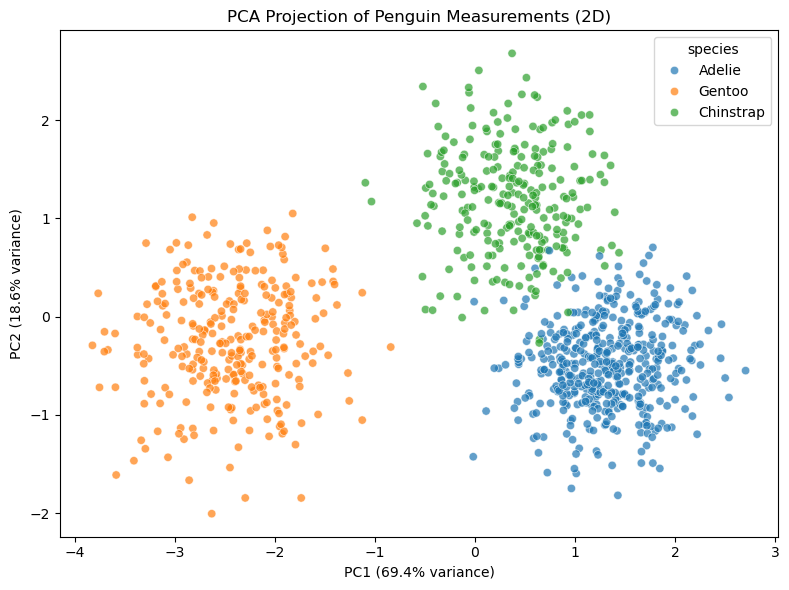

In [18]:
# Step 4-5: keep top 2 eigenvectors, project data onto them
top2_eigvecs = eigvecs[:, :2]
X_pca = X_std @ top2_eigvecs

df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['species'] = df['species']

# Step 6: plot 2D projection
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='species', alpha=0.7)
plt.title('PCA Projection of Penguin Measurements (2D)')
plt.xlabel(f'PC1 ({explained_var.iloc[0, 1]:.1f}% variance)')
plt.ylabel(f'PC2 ({explained_var.iloc[1, 1]:.1f}% variance)')
plt.tight_layout()
plt.show()

### PCA explanation

- **Standardization** puts all 4 features on the same scale, so PCA isn't dominated by `body_mass_g` (same issue as in D1).
- **Covariance matrix** shows how features vary together — e.g. `flipper_length_mm` and `body_mass_g` are strongly positively correlated (0.755), `culmen_depth_mm` is negatively correlated with most others.
- **Eigenvalues** represent how much variance each principal component captures. Here PC1 explains ~69% and PC2 ~19%, so together the 2D projection keeps about 88% of the original information.
- **The plot** shows that even in just 2 dimensions, the three species form fairly separate clusters — Gentoo especially stands apart, confirming PCA kept the meaningful structure of the original 4D data.

Compared to the raw 4-feature data, the 2D projection is much easier to visualize and still preserves most of the variance, at the cost of losing the direct physical meaning of the original measurements.

# Level C — Difficult

## C1. Advanced Sampling & Data Quality Analysis

In [19]:
diamonds = sns.load_dataset('diamonds')
print('Shape:', diamonds.shape)
diamonds.head()

Shape: (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [20]:
np.random.seed(42)

# Simple Random Sample
srs_sample = diamonds.sample(frac=0.10, random_state=42)

# Stratified sample
stratified_sample = diamonds.groupby('cut', group_keys=False, observed=True).sample(frac=0.10, random_state=42)

# Cluster sample
clusters = diamonds['color'].unique()
chosen_clusters = np.random.choice(clusters, size=3, replace=False)
cluster_sample = diamonds[diamonds['color'].isin(chosen_clusters)]

print('Chosen clusters (colors):', chosen_clusters)
sample_sizes = pd.DataFrame({
    'Sample': ['Full data', 'Simple Random (10%)', 'Stratified (10%)', 'Cluster (3 colors)'],
    'Rows': [len(diamonds), len(srs_sample), len(stratified_sample), len(cluster_sample)],
    '% of full data': [100, len(srs_sample)/len(diamonds)*100, len(stratified_sample)/len(diamonds)*100,
                        len(cluster_sample)/len(diamonds)*100]
})
sample_sizes.round(1)

Chosen clusters (colors): ['E' 'I' 'G']


,Sample,Rows,% of full data
0,Full data,53940,100.0
1,Simple Random (10%),5394,10.0
2,Stratified (10%),5394,10.0
3,Cluster (3 colors),26511,49.1


Cluster sample - picked whole 'color' groups (natural cluster identifier). Color grade is assigned at the diamond-grading stage, so diamonds within the same color form a naturally occurring group.

In [21]:
# Compare 'cut' proportions
cut_proportions = pd.DataFrame({
    'Full data': diamonds['cut'].value_counts(normalize=True),
    'Stratified sample': stratified_sample['cut'].value_counts(normalize=True)
}).round(3)
cut_proportions

,Full data,Stratified sample
cut,,
Ideal,0.400,0.400
Premium,0.256,0.256
Very Good,0.224,0.224
Good,0.091,0.091
Fair,0.030,0.030


In [22]:
# Descriptive statistics on 'price' for each sampling 
def price_stats(data):
    return pd.Series({
        'Mean': data['price'].mean(),
        'Median': data['price'].median(),
        'Variance': data['price'].var(),
        'IQR': data['price'].quantile(0.75) - data['price'].quantile(0.25)
    })

stats_comparison = pd.DataFrame({
    'Full data': price_stats(diamonds),
    'Simple Random': price_stats(srs_sample),
    'Stratified': price_stats(stratified_sample),
    'Cluster': price_stats(cluster_sample)
})
stats_comparison.round(2)

,Full data,Simple Random,Stratified,Cluster
Mean,3932.80,3895.79,4027.74,3881.76
Median,2401.00,2344.50,2518.00,2287.00
Variance,15915629.42,16149476.41,16381680.19,16227526.75
IQR,4374.25,4311.75,4488.75,4397.50


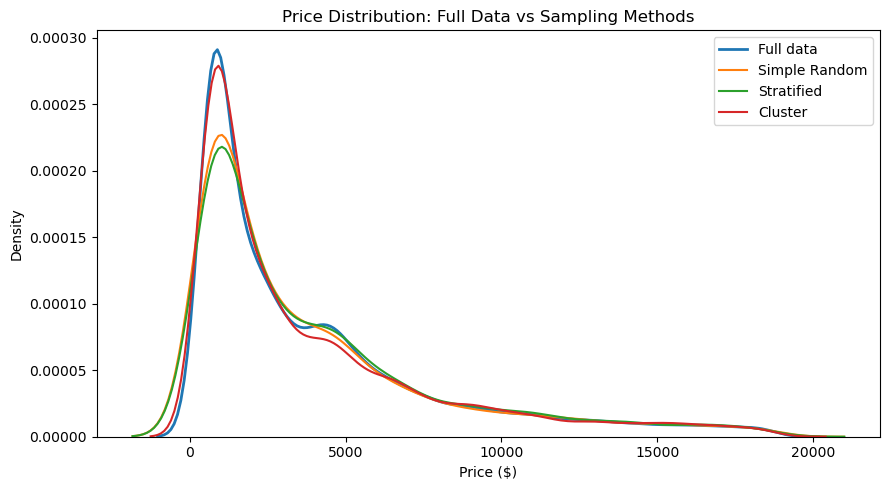

In [23]:
fig, axes = plt.subplots(1, 1, figsize=(9, 5))
sns.kdeplot(diamonds['price'], label='Full data', linewidth=2)
sns.kdeplot(srs_sample['price'], label='Simple Random')
sns.kdeplot(stratified_sample['price'], label='Stratified')
sns.kdeplot(cluster_sample['price'], label='Cluster')
plt.title('Price Distribution: Full Data vs Sampling Methods')
plt.xlabel('Price ($)')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
# Outlier detection impact
def outlier_pct(data):
    q1, q3 = data['price'].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((data['price'] < q1 - 1.5*iqr) | (data['price'] > q3 + 1.5*iqr)).sum()
    return n_out / len(data) * 100

outlier_comparison = pd.DataFrame({
    'Sample': ['Full data', 'Simple Random', 'Stratified', 'Cluster'],
    'Outlier %': [outlier_pct(diamonds), outlier_pct(srs_sample),
                  outlier_pct(stratified_sample), outlier_pct(cluster_sample)]
})
outlier_comparison.round(2)

,Sample,Outlier %
0,Full data,6.56
1,Simple Random,6.97
2,Stratified,6.41
3,Cluster,6.53


### Analytical report

**Which method preserved distributions best?**
Stratified sampling kept the `cut` category proportions almost identical to the full dataset (e.g. Ideal 40.0% vs 40.0%), and its price mean/median/IQR are also closest to the full data. Simple random sampling is close too since 10% of 54k rows is still large enough to be representative. Cluster sampling is the least reliable here — by picking only 3 out of 7 color groups, the sample can shift mean/median depending on which colors happen to have pricier diamonds, even though it still ends up close in this run.

**Impact on outlier detection**
Outlier percentage stays roughly around 6-7% across all four samples, since price outliers (very expensive diamonds) exist across cuts and colors, not tied to one stratum or cluster. Cluster sampling is riskiest for outlier detection in general, since excluding whole groups could exclude or overrepresent an entire price segment.

**Recommendations**
- Use stratified sampling when a known important category (like `cut`) must be represented proportionally.
- Simple random sampling is a safe default when the dataset is large and no strong subgroup structure exists.
- Cluster sampling is mainly useful for cost/practicality reasons (e.g. surveying whole regions/stores), not for statistical accuracy - it should be combined with more clusters or repeated sampling to reduce risk of bias.